# Clustering de la clientèle Telco

Adapté de `TP1_Correction.ipynb` aux données *Telco Customer Churn*.

**Sorties** (lues par `src/tools.py`) :
- `data/clients_clusters.csv` : les données nettoyées + une colonne `cluster`
- `models/clustering.joblib` : le pipeline (standardisation + K-Means), pour placer un nouveau client

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42
ROOT = Path("..")  # le notebook est dans notebooks/

## 1. Chargement et nettoyage

Piège : `TotalCharges` est lue comme du **texte** et contient 11 valeurs `" "` (clients avec `tenure = 0`, pas encore facturés).
`isna()` ne les voit pas. On les convertit en nombre et on les remplace par 0.

In [2]:
df = pd.read_csv(ROOT / "data/telco_churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("valeurs vides dans TotalCharges :", df["TotalCharges"].isna().sum())
print(df.loc[df["TotalCharges"].isna(), "tenure"].unique())  # -> tous à tenure = 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print(df.shape)
df.head()

valeurs vides dans TotalCharges : 11
[0]
(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Exploration

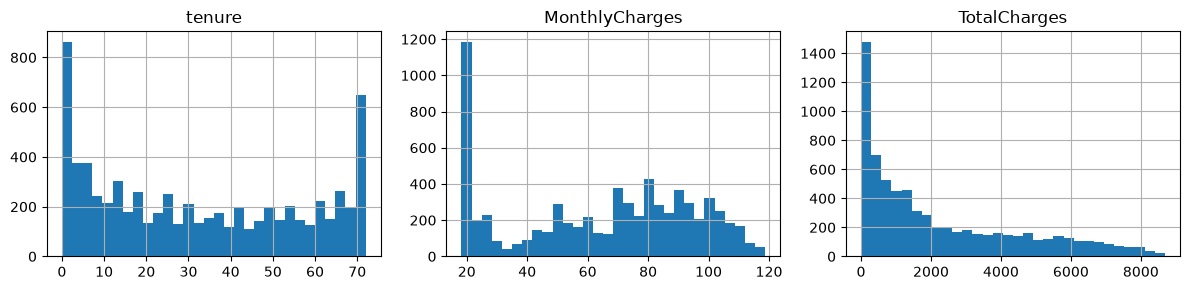

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64 

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64 

taux de churn global : 0.265


In [3]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].hist(bins=30, figsize=(12, 3), layout=(1, 3))
plt.tight_layout(); plt.show()
print(df["Contract"].value_counts(), "\n")
print(df["InternetService"].value_counts(), "\n")
print("taux de churn global :", round((df["Churn"] == "Yes").mean(), 3))

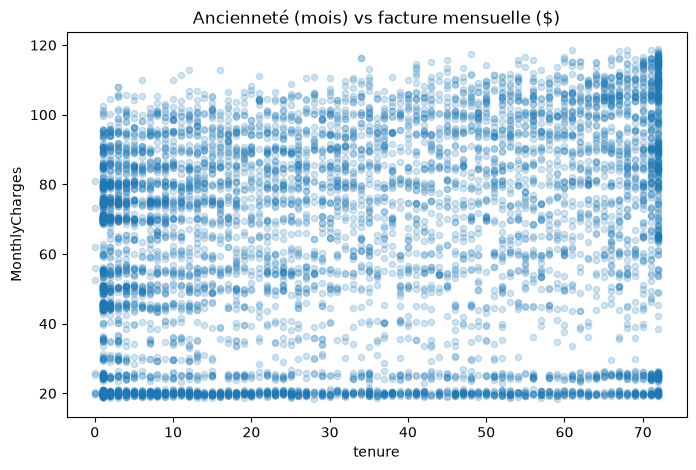

In [4]:
df.plot.scatter(x="tenure", y="MonthlyCharges", alpha=0.2)
plt.title("Ancienneté (mois) vs facture mensuelle ($)")
plt.show()

## 3. Expérience : quel jeu de variables ?

Contrairement au TP1, Telco contient surtout des variables **catégorielles**. On compare trois jeux de variables avec le score de silhouette (k de 2 à 8) :

| Jeu | Variables |
|---|---|
| A | `tenure`, `MonthlyCharges` |
| A + Total | A + `TotalCharges` (≈ tenure × MonthlyCharges : redondante) |
| B | A + `Contract`, `InternetService` en one-hot |

`customerID` et `Churn` ne sont **jamais** utilisés pour le clustering : `Churn` sert seulement à décrire les groupes ensuite.
La silhouette est calculée sur un échantillon de 3000 clients (`sample_size`) pour aller plus vite.

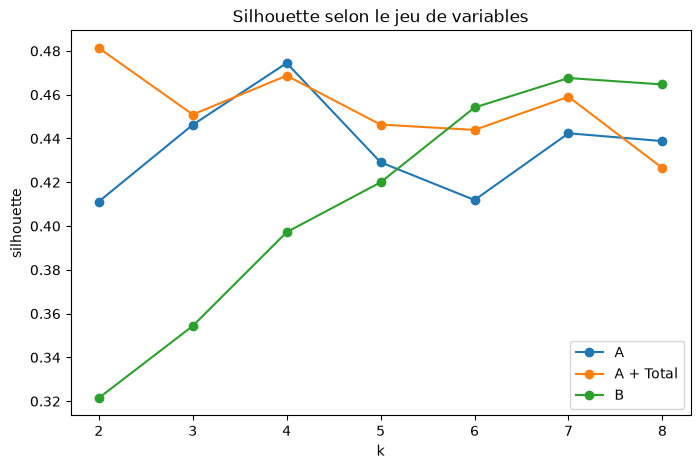

,A,A + Total,B
2,0.411,0.481,0.321
3,0.446,0.451,0.354
4,0.474,0.469,0.397
5,0.429,0.446,0.420
6,0.412,0.444,0.454
7,0.442,0.459,0.468
8,0.439,0.426,0.465


In [5]:
JEUX = {
    "A": (["tenure", "MonthlyCharges"], []),
    "A + Total": (["tenure", "MonthlyCharges", "TotalCharges"], []),
    "B": (["tenure", "MonthlyCharges"], ["Contract", "InternetService"]),
}

def preprocesseur(num, cat):
    etapes = [("num", StandardScaler(), num)]
    if cat:
        etapes.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    return ColumnTransformer(etapes)

ks = range(2, 9)
resultats = {}
for nom, (num, cat) in JEUX.items():
    X = preprocesseur(num, cat).fit_transform(df[num + cat])
    resultats[nom] = [
        silhouette_score(X, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X),
                         sample_size=3000, random_state=RANDOM_STATE)
        for k in ks
    ]

for nom, sil in resultats.items():
    plt.plot(ks, sil, marker="o", label=nom)
plt.xlabel("k"); plt.ylabel("silhouette"); plt.legend(); plt.title("Silhouette selon le jeu de variables")
plt.show()
pd.DataFrame(resultats, index=ks).round(3)

✍️ **Lecture** : le jeu A atteint sa meilleure silhouette à k = 4 (≈ 0,47). Le jeu B (avec le one-hot) a une silhouette plus faible pour les petits k : les colonnes 0/1 créent des « paquets » artificiels.
A + Total fait à peine mieux à k = 2, mais `TotalCharges` double le poids de l'ancienneté sans apporter d'information nouvelle.
On retient **le jeu A** : simple, visualisable en 2D, facile à expliquer.

## 4. Choix de k (jeu A) : coude et silhouette

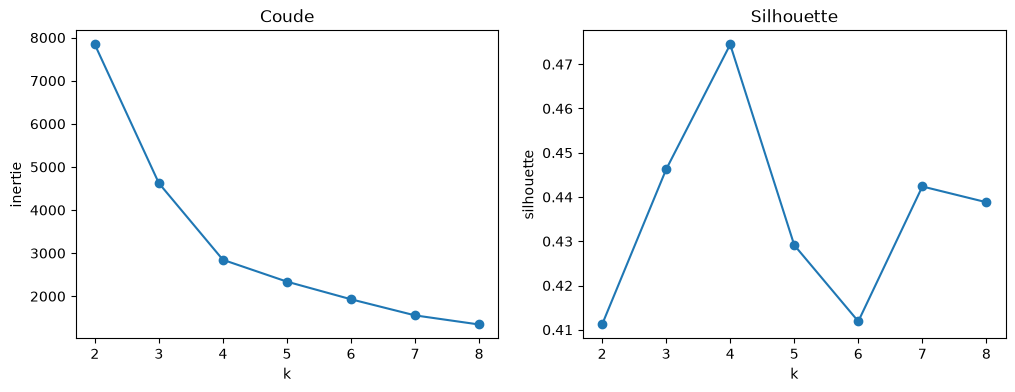

meilleur k (silhouette) : 4


In [6]:
FEATURES = ["tenure", "MonthlyCharges"]
X = StandardScaler().fit_transform(df[FEATURES])

inerties, sils = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inerties.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_, sample_size=3000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inerties, marker="o"); axes[0].set(title="Coude", xlabel="k", ylabel="inertie")
axes[1].plot(ks, sils, marker="o"); axes[1].set(title="Silhouette", xlabel="k", ylabel="silhouette")
plt.show()
print("meilleur k (silhouette) :", ks[int(np.argmax(sils))])

## 5. Modèle final : un **Pipeline**

Différence importante avec le TP1 : le scaler et le K-Means sont réunis dans un `Pipeline`.
Ainsi, l'outil *Details* peut placer un **nouveau client** avec `pipeline.predict(...)` en lui appliquant exactement la même standardisation.

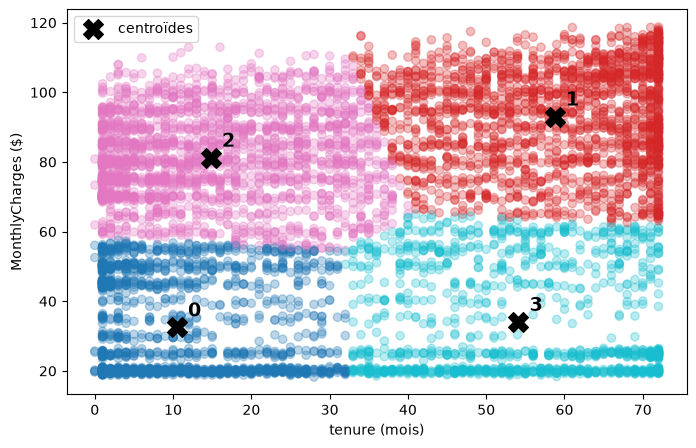

In [7]:
K = 4
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)),
])
df["cluster"] = pipeline.fit_predict(df[FEATURES])

centres = pipeline["scaler"].inverse_transform(pipeline["kmeans"].cluster_centers_)
plt.scatter(df["tenure"], df["MonthlyCharges"], c=df["cluster"], cmap="tab10", alpha=0.3)
plt.scatter(centres[:, 0], centres[:, 1], c="black", marker="X", s=200, label="centroïdes")
for i, (x, y) in enumerate(centres):
    plt.annotate(str(i), (x, y), xytext=(8, 8), textcoords="offset points", fontsize=14, weight="bold")
plt.xlabel("tenure (mois)"); plt.ylabel("MonthlyCharges ($)"); plt.legend()
plt.show()

## 6. Profil des groupes

On décrit chaque groupe avec les variables du clustering **et** d'autres variables qui n'y ont pas servi (contrat, internet, churn).
Le taux de churn par groupe est ce qui intéresse le plus le marketing.

In [8]:
profil = (
    df.assign(churn=df["Churn"] == "Yes",
              mensuel=df["Contract"] == "Month-to-month",
              fibre=df["InternetService"] == "Fiber optic",
              senior=df["SeniorCitizen"] == 1)
    .groupby("cluster")
    .agg(effectif=("customerID", "size"),
         tenure=("tenure", "mean"),
         facture_mensuelle=("MonthlyCharges", "mean"),
         total_facture=("TotalCharges", "mean"),
         part_contrat_mensuel=("mensuel", "mean"),
         part_fibre=("fibre", "mean"),
         part_senior=("senior", "mean"),
         taux_churn=("churn", "mean"))
    .round(2)
)
profil

,effectif,tenure,facture_mensuelle,total_facture,part_contrat_mensuel,part_fibre,part_senior,taux_churn
cluster,,,,,,,,
0,1732,10.49,32.47,332.67,0.73,0.00,0.07,0.25
1,1952,58.75,93.02,5475.00,0.27,0.70,0.22,0.16
2,2204,14.81,81.22,1213.73,0.87,0.78,0.23,0.49
3,1155,54.12,34.03,1833.52,0.15,0.00,0.08,0.05


✍️ **À compléter après lecture du tableau** : donner un nom parlant à chaque groupe (ex. « nouveaux clients à petite facture », « fidèles premium »…).
Les numéros de groupe dépendent de `random_state` : ne pas les coder en dur ailleurs.

## 7. Robustesse : K-Means vs CAH (facultatif)

La CAH est trop lourde sur 7 000 clients : on la fait sur un échantillon de 2 000 et on compare avec les étiquettes K-Means de ces mêmes clients (ARI : 1 = partitions identiques, 0 = hasard).

In [9]:
ech = df.sample(2000, random_state=RANDOM_STATE)
X_ech = pipeline["scaler"].transform(ech[FEATURES])
labels_cah = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_ech)
print("ARI K-Means / CAH :", round(adjusted_rand_score(ech["cluster"], labels_cah), 3))
pd.crosstab(ech["cluster"], labels_cah)

ARI K-Means / CAH : 0.632


col_0,0,1,2,3
cluster,,,,
0,0,480,6,0
1,481,0,67,0
2,187,45,12,388
3,0,3,331,0


## 8. Sauvegarde (utilisée par `src/tools.py`)

In [10]:
(ROOT / "models").mkdir(exist_ok=True)
joblib.dump({"pipeline": pipeline, "features": FEATURES}, ROOT / "models/clustering.joblib")
df.to_csv(ROOT / "data/clients_clusters.csv", index=False)
print("sauvegardé :", ROOT / "models/clustering.joblib", "et", ROOT / "data/clients_clusters.csv")

sauvegardé : ../models/clustering.joblib et ../data/clients_clusters.csv


In [11]:
# Vérification : recharger et placer un nouveau client
modele = joblib.load(ROOT / "models/clustering.joblib")
nouveau = pd.DataFrame([{"tenure": 3, "MonthlyCharges": 95.0}])
print("groupe du nouveau client :", modele["pipeline"].predict(nouveau[modele["features"]])[0])

groupe du nouveau client : 2
